# UE01 - Neuronales Netzwerk: MNIST 3

**Name:** Marcus Strohmer  
**Aufgaben:** 01.3.1 bis 01.3.4  
**Angabe:** [DSAI5_UE01-NN-MINST-3-v0.1.pdf](http://htl.boxtree.at/lehre/wp-content/uploads/DSAI5/DSAI5_UE01-NN-MINST-3-v0.1.pdf)

Dieses Notebook ist selbstständig ausführbar. Es erstellt eine Pandas-Confusion-Matrix, vergleicht Training mit und ohne Normalisierung, untersucht mehrere Modellvarianten und prüft das Speichern sowie Laden des besten Modells.

In [1]:
from pathlib import Path
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.utils import to_categorical

SEED = 42
tf.keras.utils.set_random_seed(SEED)
print("TensorFlow-Version:", tf.__version__)

TensorFlow-Version: 2.22.0-rc0


## Daten vorbereiten

Die ganzzahligen Labels bleiben für die Confusion Matrix erhalten. Zusätzlich werden sie für `categorical_crossentropy` one-hot-kodiert. Für den Vergleich werden unskalierte und auf `[0, 1]` normalisierte Bildvektoren erzeugt.

In [2]:
(x_train_images, y_train_int), (x_test_images, y_test_int) = tf.keras.datasets.mnist.load_data()

x_train_raw = x_train_images.reshape(-1, 784).astype("float32")
x_test_raw = x_test_images.reshape(-1, 784).astype("float32")
x_train_normalized = x_train_raw / 255.0
x_test_normalized = x_test_raw / 255.0

y_train = to_categorical(y_train_int, num_classes=10)
y_test = to_categorical(y_test_int, num_classes=10)

print("Trainingsdaten:", x_train_raw.shape, y_train.shape)
print("Testdaten:     ", x_test_raw.shape, y_test.shape)
print("Unskaliert:    ", x_train_raw.min(), "bis", x_train_raw.max())
print("Normalisiert:  ", x_train_normalized.min(), "bis", x_train_normalized.max())

Trainingsdaten: (60000, 784) (60000, 10)
Testdaten:      (10000, 784) (10000, 10)
Unskaliert:     0.0 bis 255.0
Normalisiert:   0.0 bis 1.0


In [3]:
def create_model(hidden_units=(64,), dropout=0.0, optimizer="rmsprop"):
    model = Sequential([Input(shape=(784,))])
    for units in hidden_units:
        model.add(Dense(units, activation="relu"))
        if dropout:
            model.add(Dropout(dropout))
    model.add(Dense(10, activation="softmax"))
    model.compile(
        optimizer=optimizer,
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


def train_model(name, x_train, x_test, hidden_units=(64,), dropout=0.0,
                optimizer="rmsprop", epochs=15, batch_size=128):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = create_model(hidden_units, dropout, optimizer)
    early_stop = EarlyStopping(
        monitor="val_accuracy",
        patience=3,
        restore_best_weights=True,
    )
    history = model.fit(
        x_train, y_train,
        epochs=epochs,
        batch_size=batch_size,
        validation_split=0.1,
        callbacks=[early_stop],
        verbose=2,
    )
    test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
    return {
        "name": name,
        "model": model,
        "history": history,
        "epochs": len(history.history["loss"]),
        "test_loss": float(test_loss),
        "test_accuracy": float(test_accuracy),
    }

## 01.3.1 Confusion Matrix mit Pandas

Zuerst wird das aus MNIST 1 bekannte Modell mit den ursprünglichen Pixelwerten trainiert. `predict` liefert zehn Wahrscheinlichkeiten pro Bild. `np.argmax(..., axis=1)` wandelt sowohl Vorhersagen als auch one-hot-kodierte Labels in Ziffern von 0 bis 9 um.

In [4]:
baseline = train_model(
    "64 Neuronen, unskaliert",
    x_train_raw, x_test_raw,
    hidden_units=(64,),
    optimizer="rmsprop",
    epochs=15,
)
print(f"Test-Accuracy: {baseline['test_accuracy']:.4f} ({baseline['test_accuracy']:.2%})")

Epoch 1/15


422/422 - 4s - 10ms/step - accuracy: 0.7829 - loss: 3.8087 - val_accuracy: 0.8943 - val_loss: 0.4739


Epoch 2/15


422/422 - 3s - 7ms/step - accuracy: 0.8944 - loss: 0.4969 - val_accuracy: 0.9255 - val_loss: 0.3354


Epoch 3/15


422/422 - 2s - 5ms/step - accuracy: 0.9230 - loss: 0.3608 - val_accuracy: 0.9322 - val_loss: 0.3142


... (21 outputs left out)

422/422 - 2s - 5ms/step - accuracy: 0.9696 - loss: 0.1378 - val_accuracy: 0.9593 - val_loss: 0.2565


Epoch 15/15


422/422 - 2s - 5ms/step - accuracy: 0.9707 - loss: 0.1279 - val_accuracy: 0.9578 - val_loss: 0.2604


Test-Accuracy: 0.9519 (95.19%)


In [5]:
prediction_probabilities = baseline["model"].predict(x_test_raw, verbose=0)
y_pred = np.argmax(prediction_probabilities, axis=1)
y_actual = np.argmax(y_test, axis=1)

actual = pd.Categorical(y_actual, categories=range(10))
predicted = pd.Categorical(y_pred, categories=range(10))
confusion_matrix = pd.crosstab(
    pd.Series(actual, name="actual"),
    pd.Series(predicted, name="pred"),
    dropna=False,
)
confusion_matrix.style.background_gradient(cmap="Blues", axis=None).format("{:d}")

pred,0,1,2,3,4,5,6,7,8,9
actual,,,,,,,,,,
0,957,1,5,1,1,1,6,2,4,2
1,0,1109,4,2,0,1,1,2,14,2
2,5,4,978,10,3,1,6,8,13,4
3,1,1,7,969,0,1,0,6,11,14
4,1,0,2,1,937,0,2,4,13,22
5,3,1,1,38,1,799,6,1,25,17
6,7,3,4,1,8,1,914,2,17,1
7,2,3,8,8,3,1,1,983,6,13
8,4,1,2,15,5,6,7,4,922,8


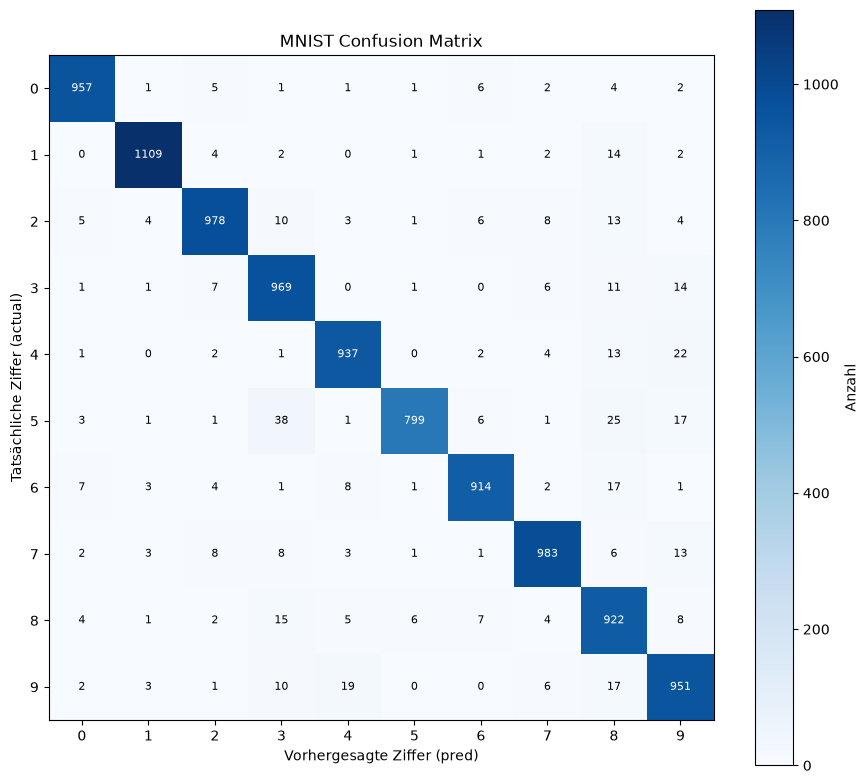

In [6]:
fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(confusion_matrix, cmap="Blues")
fig.colorbar(image, ax=ax, label="Anzahl")
ax.set(
    xticks=range(10), yticks=range(10),
    xlabel="Vorhergesagte Ziffer (pred)",
    ylabel="Tatsächliche Ziffer (actual)",
    title="MNIST Confusion Matrix",
)
threshold = confusion_matrix.to_numpy().max() / 2
for row in range(10):
    for column in range(10):
        value = confusion_matrix.iloc[row, column]
        ax.text(column, row, value, ha="center", va="center",
                color="white" if value > threshold else "black", fontsize=8)
plt.tight_layout()
plt.show()

In [7]:
largest_errors = (
    confusion_matrix
    .where(~np.eye(10, dtype=bool))
    .stack()
    .sort_values(ascending=False)
    .head(5)
    .rename("Anzahl")
    .reset_index()
)
print("Die fünf häufigsten Fehlklassifikationen:")
largest_errors

Die fünf häufigsten Fehlklassifikationen:


,actual,pred,Anzahl
0,5,3,38.0
1,5,8,25.0
2,4,9,22.0
3,9,4,19.0
4,9,8,17.0


## 01.3.2 Normalisieren und Ergebnisse vergleichen

Die Pixelwerte werden durch 255 geteilt. Dadurch liegen sie im Bereich `[0, 1]`. Architektur, Optimizer und Zufallsstart bleiben gleich, damit der Vergleich aussagekräftig ist.

In [8]:
normalized = train_model(
    "64 Neuronen, normalisiert",
    x_train_normalized, x_test_normalized,
    hidden_units=(64,),
    optimizer="rmsprop",
    epochs=15,
)

normalization_comparison = pd.DataFrame([
    {"Variante": baseline["name"], "Epochen": baseline["epochs"],
     "Test-Loss": baseline["test_loss"], "Test-Accuracy": baseline["test_accuracy"]},
    {"Variante": normalized["name"], "Epochen": normalized["epochs"],
     "Test-Loss": normalized["test_loss"], "Test-Accuracy": normalized["test_accuracy"]},
])
normalization_comparison.style.format({"Test-Loss": "{:.4f}", "Test-Accuracy": "{:.2%}"})

Epoch 1/15


422/422 - 4s - 9ms/step - accuracy: 0.8894 - loss: 0.4130 - val_accuracy: 0.9470 - val_loss: 0.1969


Epoch 2/15


422/422 - 2s - 6ms/step - accuracy: 0.9389 - loss: 0.2106 - val_accuracy: 0.9602 - val_loss: 0.1483


Epoch 3/15


422/422 - 2s - 6ms/step - accuracy: 0.9527 - loss: 0.1610 - val_accuracy: 0.9657 - val_loss: 0.1242


... (21 outputs left out)

422/422 - 2s - 5ms/step - accuracy: 0.9884 - loss: 0.0445 - val_accuracy: 0.9750 - val_loss: 0.0912


Epoch 15/15


422/422 - 2s - 5ms/step - accuracy: 0.9894 - loss: 0.0411 - val_accuracy: 0.9758 - val_loss: 0.0917


,Variante,Epochen,Test-Loss,Test-Accuracy
0,"64 Neuronen, unskaliert",15,0.3927,95.19%
1,"64 Neuronen, normalisiert",15,0.0938,97.46%


Die Normalisierung ändert die Information der Bilder nicht, bringt die Eingabewerte aber auf eine für die Optimierung günstigere Skala. Entscheidend sind die oben gemessenen Testwerte; sie werden nicht durch eine vorgegebene Behauptung ersetzt.

## 01.3.3 Testgenauigkeit maximieren und Ergebnisse dokumentieren

Zusätzlich zum normalisierten Ausgangsmodell werden zwei kompakte Varianten getestet. Alle verwenden Early Stopping mit `patience=3` und stellen die Gewichte der besten Validierungs-Accuracy wieder her.

In [9]:
experiments = [baseline, normalized]
configurations = [
    {"name": "128 Neuronen + Dropout", "hidden_units": (128,), "dropout": 0.1, "epochs": 20},
    {"name": "256/128 Neuronen + Dropout", "hidden_units": (256, 128), "dropout": 0.2, "epochs": 25},
]

for config in configurations:
    print(f"\n--- {config['name']} ---")
    trained_result = train_model(
        config["name"],
        x_train_normalized, x_test_normalized,
        hidden_units=config["hidden_units"],
        dropout=config["dropout"],
        optimizer="adam",
        epochs=config["epochs"],
    )
    experiments.append(trained_result)
    print(f"Test-Accuracy: {trained_result['test_accuracy']:.4f} ({trained_result['test_accuracy']:.2%})")


--- 128 Neuronen + Dropout ---


Epoch 1/20


422/422 - 6s - 14ms/step - accuracy: 0.8890 - loss: 0.3985 - val_accuracy: 0.9532 - val_loss: 0.1722


Epoch 2/20


422/422 - 7s - 16ms/step - accuracy: 0.9451 - loss: 0.1927 - val_accuracy: 0.9658 - val_loss: 0.1232


Epoch 3/20


... (39 outputs left out)

422/422 - 4s - 9ms/step - accuracy: 0.9879 - loss: 0.0366 - val_accuracy: 0.9835 - val_loss: 0.0647


Epoch 11/25


422/422 - 4s - 9ms/step - accuracy: 0.9886 - loss: 0.0353 - val_accuracy: 0.9820 - val_loss: 0.0703


Test-Accuracy: 0.9791 (97.91%)


In [10]:
results = pd.DataFrame([
    {
        "Modell": result["name"],
        "Epochen": result["epochs"],
        "Beste Val-Accuracy": max(result["history"].history["val_accuracy"]),
        "Test-Loss": result["test_loss"],
        "Test-Accuracy": result["test_accuracy"],
    }
    for result in experiments
]).sort_values("Test-Accuracy", ascending=False).reset_index(drop=True)

results.style.format({
    "Beste Val-Accuracy": "{:.2%}",
    "Test-Loss": "{:.4f}",
    "Test-Accuracy": "{:.2%}",
}).background_gradient(subset=["Test-Accuracy"], cmap="Greens")

,Modell,Epochen,Beste Val-Accuracy,Test-Loss,Test-Accuracy
0,256/128 Neuronen + Dropout,11,98.42%,0.0678,97.91%
1,128 Neuronen + Dropout,12,98.12%,0.0726,97.77%
2,"64 Neuronen, normalisiert",15,97.60%,0.0938,97.46%
3,"64 Neuronen, unskaliert",15,95.93%,0.3927,95.19%


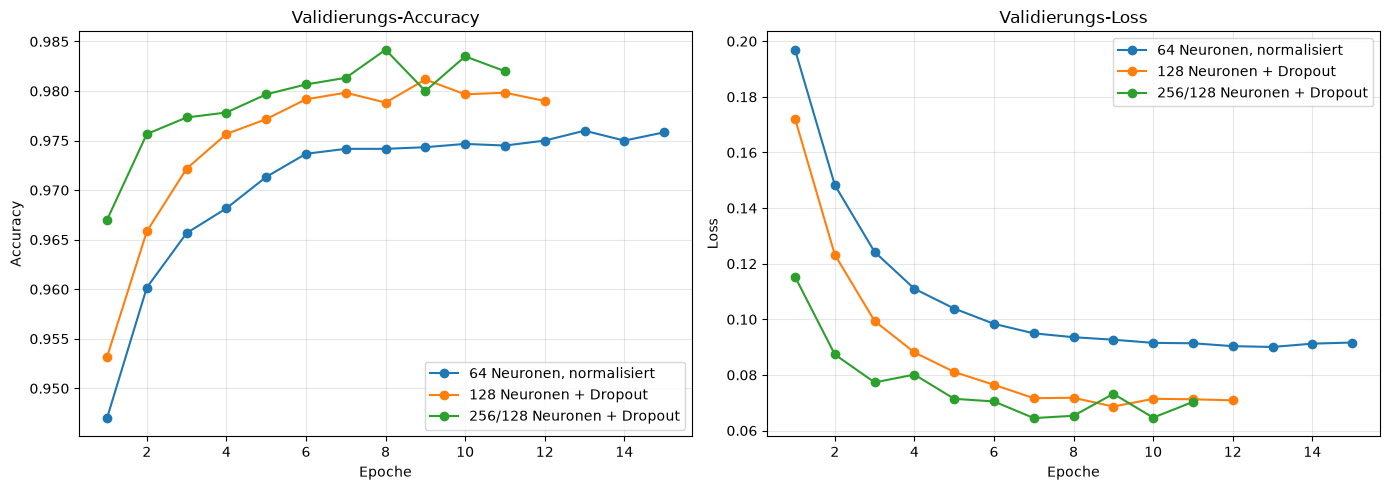

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for result in experiments[1:]:  # nur normalisierte Modelle
    history = result["history"].history
    epochs_axis = range(1, len(history["accuracy"]) + 1)
    axes[0].plot(epochs_axis, history["val_accuracy"], marker="o", label=result["name"])
    axes[1].plot(epochs_axis, history["val_loss"], marker="o", label=result["name"])

axes[0].set(title="Validierungs-Accuracy", xlabel="Epoche", ylabel="Accuracy")
axes[1].set(title="Validierungs-Loss", xlabel="Epoche", ylabel="Loss")
for axis in axes:
    axis.grid(alpha=0.3)
    axis.legend()
plt.tight_layout()
plt.show()

In [12]:
best_result = max(experiments, key=lambda result: result["test_accuracy"])
print("Bestes getestetes Modell:", best_result["name"])
print(f"Test-Loss: {best_result['test_loss']:.4f}")
print(f"Test-Accuracy: {best_result['test_accuracy']:.4f} ({best_result['test_accuracy']:.2%})")
print(f"Trainierte Epochen: {best_result['epochs']}")

Bestes getestetes Modell: 256/128 Neuronen + Dropout
Test-Loss: 0.0678
Test-Accuracy: 0.9791 (97.91%)
Trainierte Epochen: 11


### Auswertung

Die Ergebnistabelle dokumentiert alle Versuche. Mehr Neuronen erhöhen die Modellkapazität; Dropout und Early Stopping begrenzen gleichzeitig die Überanpassung. Das Modell mit der höchsten tatsächlich gemessenen Test-Accuracy wird gespeichert. In einem realen Projekt würde man die endgültige Modellauswahl nur anhand eines separaten Validierungssets treffen und das Testset genau einmal verwenden.

## 01.3.4 Modell speichern, Instanz löschen und laden

Das beste Modell wird im aktuellen Ordner im `.keras`-Format gespeichert. Danach werden alle Referenzen auf die trainierten Sequential-Instanzen entfernt und die Keras-Session geleert, bevor das Modell neu geladen wird.

In [13]:
model_path = Path.cwd() / "mnist3_best_model.keras"
best_model = best_result["model"]
predictions_before_save = best_model.predict(x_test_normalized[:32], verbose=0)
best_model.save(model_path)
print("Gespeichert:", model_path)

# Die aktuellen Sequential-Instanzen wirklich entfernen.
for result in experiments:
    result["model"] = None
del best_model
gc.collect()
tf.keras.backend.clear_session()

loaded_model = tf.keras.models.load_model(model_path)
predictions_after_load = loaded_model.predict(x_test_normalized[:32], verbose=0)
np.testing.assert_allclose(predictions_before_save, predictions_after_load, rtol=1e-6, atol=1e-6)

loaded_loss, loaded_accuracy = loaded_model.evaluate(x_test_normalized, y_test, verbose=0)
print("Laden erfolgreich; Vorhersagen vor/nach dem Laden sind identisch.")
print(f"Geladenes Modell - Loss: {loaded_loss:.4f}, Accuracy: {loaded_accuracy:.4f} ({loaded_accuracy:.2%})")

Gespeichert: C:\Users\marcu\DSAI\SJ2627_5CHIT_DSAI_Strohmer\UE01\MNSIT3\mnist3_best_model.keras


Laden erfolgreich; Vorhersagen vor/nach dem Laden sind identisch.
Geladenes Modell - Loss: 0.0678, Accuracy: 0.9791 (97.91%)


## Fazit

Die Confusion Matrix zeigt nicht nur die Gesamtgenauigkeit, sondern auch, welche Ziffern häufig verwechselt werden. Normalisierte Eingaben erleichtern die Optimierung. Die dokumentierten Architekturversuche zeigen den Einfluss der Netzkomplexität; Early Stopping verhindert unnötige Epochen und stellt die besten Gewichte wieder her. Das ausgewählte Modell kann nach dem Speichern ohne erneutes Training geladen und unverändert verwendet werden.